# FIN-01 · Três análises e insights

- **Tarefa:** FIN-01, três análises com consulta SQL no DW e um gráfico cada
- **Responsável:** Davi Mello
- **Entrada:** o Data Warehouse no PostgreSQL (`fato_pessoa_sinistro` + 8 dimensões)
- **Consultas:** `sql/analises/analises.sql` (um bloco por consulta, lido aqui pelo nome)
- **Saídas:** os gráficos em `docs/relatorio/img/` e a seção 6 do relatório

As três perguntas: **quem morre**, **onde se morre** e **quando se morre**. A medida principal é a **letalidade**: óbitos ÷ pessoas envolvidas (`SUM(flag_obito) / SUM(qtd_pessoas)`).

## 1. Setup

In [1]:
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

# Raiz do repositório: sobe de pasta em pasta até achar a pasta .git
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
os.chdir(RAIZ)   # para achar src/ e o .env

from src.conexao import obter_engine

ESQUEMA   = "public"     # estrela da ETL; "dw_elt" dá o mesmo resultado (as duas são idênticas)
CONSULTAS = RAIZ / "sql" / "analises" / "analises.sql"
IMAGENS   = RAIZ / "docs" / "relatorio" / "img"
IMAGENS.mkdir(parents=True, exist_ok=True)

engine = obter_engine()

In [2]:
def ler_consultas(arquivo: Path) -> dict:
    """Separa o arquivo em blocos '-- [nome]' e devolve {nome: sql}."""
    partes = re.split(r"^-- \[(\w+)\]\s*$", arquivo.read_text(encoding="utf-8"), flags=re.M)
    return {nome: sql.strip() for nome, sql in zip(partes[1::2], partes[2::2])}

SQL = ler_consultas(CONSULTAS)

def consulta(nome: str) -> pd.DataFrame:
    """Roda uma consulta do arquivo no esquema escolhido."""
    with engine.begin() as conexao:
        conexao.execute(text(f"SET LOCAL search_path TO {ESQUEMA}"))
        return pd.read_sql(text(SQL[nome]), conexao)

print(len(SQL), "consultas:", ", ".join(SQL))

19 consultas: panorama_ano, a1_grupo, a1_moto_ano, a1_moto_perfil, a1_sexo, a1_pedestre_idade, a1_idosos_pedestres, a2_tipo_via, a2_cenarios, a2_local_obito, a2_dias_ate_obito, a2_regiao, a2_capital, a3_dia_semana, a3_tipo_dia, a3_feriados, a3_fim_de_semana_grupos, a3_mes, qualidade_preenchimento


In [3]:
# estilo único dos gráficos: barras finas, grade discreta, textos em cinza escuro
AZUL, LARANJA = "#2a78d6", "#eb6834"
TEXTO, TEXTO_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": GRADE, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRADE,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TEXTO,
    "axes.titlelocation": "left", "legend.frameon": False, "axes.axisbelow": True,
})

def br(valor: float, casas: int = 1) -> str:
    """Número no formato brasileiro (vírgula decimal)."""
    return f"{valor:.{casas}f}".replace(".", ",")

def salvar(fig, nome: str):
    fig.savefig(IMAGENS / nome, dpi=160, bbox_inches="tight")
    print("salvo:", (IMAGENS / nome).relative_to(RAIZ))

## 2. Panorama

In [4]:
consulta("panorama_ano")

,ano,sinistros,pessoas,obitos,letalidade
0,2021.0,128207,260886,4858,1.86
1,2022.0,132358,266128,5445,2.05
2,2023.0,142130,279963,5490,1.96
3,NaN,402695,806977,15793,1.96


## 3. Análise 1: quem morre

O pedestre vem de `tipo_de_vitima`; os demais grupos vêm do veículo em que a vítima estava (`tipo_veiculo_vitima`).

In [5]:
grupos = consulta("a1_grupo")
grupos

,grupo,pessoas,obitos,letalidade,pct_pessoas,pct_obitos
0,MOTOCICLETA,274658,6357,2.31,34.0,40.3
1,AUTOMOVEL,315274,3725,1.18,39.1,23.6
2,PEDESTRE,46173,3594,7.78,5.7,22.8
3,BICICLETA,1124,1042,92.70,0.1,6.6
4,CAMINHAO,22332,597,2.67,2.8,3.8
5,NÃO INFORMADO,123608,321,0.26,15.3,2.0
6,ONIBUS,16336,99,0.61,2.0,0.6
7,OUTROS,7472,58,0.78,0.9,0.4


In [6]:
pd.concat([consulta("a1_moto_ano"), consulta("a1_moto_perfil")], axis=1)

,ano,pessoas,obitos,mortos,pct_homens,pct_condutores,idade_mediana,pct_18_24,pct_18_34
0,2021,88516,1944,6357.0,89.1,89.5,31.0,28.3,56.0
1,2022,91058,2132,NaN,NaN,NaN,NaN,NaN,NaN
2,2023,95084,2281,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
consulta("a1_pedestre_idade")

,faixa,pessoas,obitos,letalidade
0,0-17,5780,132,2.28
1,18-29,8617,291,3.38
2,30-44,11880,622,5.24
3,45-59,9870,780,7.90
4,60-79,7772,891,11.46
5,80+,1316,231,17.55
6,não informada,938,647,68.98


In [8]:
pd.concat([consulta("a1_sexo"), consulta("a1_idosos_pedestres")], axis=1)

,sexo,pessoas,obitos,letalidade,pct_obitos,mortos_60_mais,pct_pedestres
0,MASCULINO,580447,13106,2.26,83.0,2642.0,42.5
1,FEMININO,222164,2621,1.18,16.6,NaN,NaN
2,NÃO INFORMADO,4366,66,1.51,0.4,NaN,NaN


salvo: docs/relatorio/img/analise_1_quem_morre.png


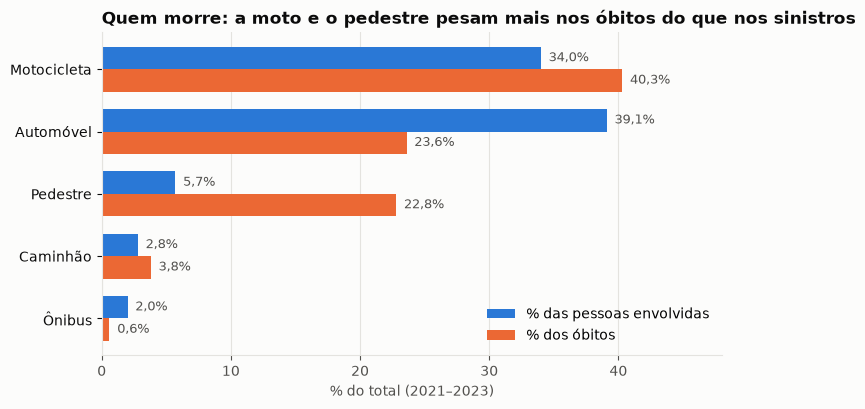

In [9]:
# Gráfico 1: participação nas pessoas envolvidas × participação nos óbitos
ROTULOS = {"MOTOCICLETA": "Motocicleta", "AUTOMOVEL": "Automóvel", "PEDESTRE": "Pedestre",
           "CAMINHAO": "Caminhão", "ONIBUS": "Ônibus"}
g = grupos[grupos["grupo"].isin(ROTULOS)].set_index("grupo").loc[list(ROTULOS)]

fig, ax = plt.subplots(figsize=(8, 4.2))
y = range(len(g))[::-1]
altura = 0.36
b1 = ax.barh([v + altura / 2 for v in y], g["pct_pessoas"], height=altura, color=AZUL, label="% das pessoas envolvidas")
b2 = ax.barh([v - altura / 2 for v in y], g["pct_obitos"], height=altura, color=LARANJA, label="% dos óbitos")
for barras in (b1, b2):
    for barra in barras:
        ax.text(barra.get_width() + 0.6, barra.get_y() + barra.get_height() / 2, br(barra.get_width()) + "%",
                va="center", fontsize=9, color=TEXTO_2)
ax.set_yticks(list(y), [ROTULOS[i] for i in g.index])
ax.set_xlabel("% do total (2021–2023)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 48)
ax.set_title("Quem morre: a moto e o pedestre pesam mais nos óbitos do que nos sinistros")
ax.legend(loc="lower right")
salvar(fig, "analise_1_quem_morre.png")
plt.show()

## 4. Análise 2: onde se morre

In [10]:
consulta("a2_tipo_via")

,tipo_via,pessoas,obitos,letalidade,pct_pessoas,pct_obitos
0,VIAS URBANAS,672411,7982,1.19,83.3,50.5
1,ESTRADAS E RODOVIAS,133593,6900,5.16,16.6,43.7
2,NÃO INFORMADO,973,911,93.63,0.1,5.8


In [11]:
cenarios = consulta("a2_cenarios")
cenarios

,grupo,tipo_via,pessoas,obitos,letalidade
0,Demais,ESTRADAS E RODOVIAS,88193,3236,3.67
1,Demais,VIAS URBANAS,397479,2194,0.55
2,Motociclistas,ESTRADAS E RODOVIAS,41677,2236,5.37
3,Motociclistas,VIAS URBANAS,232704,3844,1.65
4,Pedestres,ESTRADAS E RODOVIAS,3723,1428,38.36
5,Pedestres,VIAS URBANAS,42228,1944,4.60
6,Todos,ESTRADAS E RODOVIAS,133593,6900,5.16
7,Todos,VIAS URBANAS,672411,7982,1.19


In [12]:
consulta("a2_local_obito")

,tipo_via,local_obito,obitos,pct
0,ESTRADAS E RODOVIAS,VIA,4241,61.5
1,ESTRADAS E RODOVIAS,ESTABELECIMENTO DE SAUDE,2429,35.2
2,ESTRADAS E RODOVIAS,OUTROS,186,2.7
3,ESTRADAS E RODOVIAS,NÃO INFORMADO,44,0.6
4,VIAS URBANAS,ESTABELECIMENTO DE SAUDE,4719,59.1
5,VIAS URBANAS,VIA,2909,36.4
6,VIAS URBANAS,OUTROS,301,3.8
7,VIAS URBANAS,NÃO INFORMADO,53,0.7


In [13]:
pd.concat([consulta("a2_dias_ate_obito"), consulta("a2_capital")], axis=1)

,mesmo_dia,ate_1_dia,ate_7_dias,local,pessoas,obitos,letalidade
0,81.1,87.2,94.2,CAPITAL,186723,2525,1.35
1,NaN,NaN,NaN,DEMAIS MUNICÍPIOS,620254,13268,2.14


In [14]:
consulta("a2_regiao")

,regiao_administrativa,pessoas,obitos,letalidade,pct_pessoas_rodovia,pct_obitos_rodovia
0,REGISTRO,5132,264,5.14,56.4,82.2
1,ITAPEVA,8135,290,3.56,30.2,62.1
2,CAMPINAS,125966,3043,2.42,24.2,52.8
3,SOROCABA,53395,1248,2.34,25.9,55.0
4,SÃO JOSÉ DOS CAMPOS,43707,1011,2.31,25.3,53.0
5,CENTRAL,22862,483,2.11,16.2,49.7
6,BAURU,23550,477,2.03,18.0,53.0
7,FRANCA,17629,339,1.92,12.4,48.4
8,BARRETOS,10078,188,1.87,16.6,49.5
9,BAIXADA SANTISTA,38979,721,1.85,18.4,47.6


salvo: docs/relatorio/img/analise_2_onde_se_morre.png


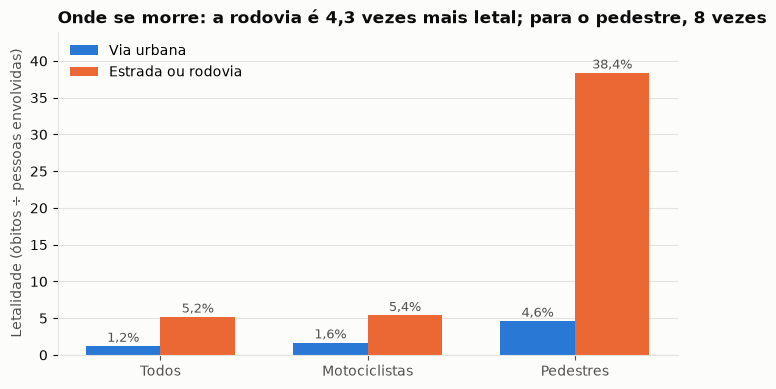

In [15]:
# Gráfico 2: letalidade em via urbana × rodovia, para todos, motociclistas e pedestres
ORDEM = ["Todos", "Motociclistas", "Pedestres"]
tab = cenarios.pivot(index="grupo", columns="tipo_via", values="letalidade").loc[ORDEM]

fig, ax = plt.subplots(figsize=(8, 4.2))
x = range(len(tab))
largura = 0.36
b1 = ax.bar([v - largura / 2 for v in x], tab["VIAS URBANAS"], width=largura, color=AZUL, label="Via urbana")
b2 = ax.bar([v + largura / 2 for v in x], tab["ESTRADAS E RODOVIAS"], width=largura, color=LARANJA, label="Estrada ou rodovia")
for barras in (b1, b2):
    for barra in barras:
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.6, br(barra.get_height()) + "%",
                ha="center", fontsize=9, color=TEXTO_2)
ax.set_xticks(list(x), ORDEM)
ax.set_ylabel("Letalidade (óbitos ÷ pessoas envolvidas)")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, 44)
ax.set_title("Onde se morre: a rodovia é 4,3 vezes mais letal; para o pedestre, 8 vezes")
ax.legend(loc="upper left")
salvar(fig, "analise_2_onde_se_morre.png")
plt.show()

## 5. Análise 3: quando se morre

In [16]:
dias = consulta("a3_dia_semana")
dias

,dia_semana,nome_dia_semana,pessoas,obitos,letalidade
0,1,SEGUNDA-FEIRA,107579,1895,1.76
1,2,TERÇA-FEIRA,107408,1733,1.61
2,3,QUARTA-FEIRA,110469,1825,1.65
3,4,QUINTA-FEIRA,112395,1837,1.63
4,5,SEXTA-FEIRA,130292,2317,1.78
5,6,SÁBADO,130210,3076,2.36
6,7,DOMINGO,108624,3110,2.86


In [17]:
tipo_dia = consulta("a3_tipo_dia")
tipo_dia

,tipo_dia,dias,pessoas,obitos,pessoas_por_dia,obitos_por_dia,letalidade
0,DIA ÚTIL,760,554750,9243,730.0,12.2,1.67
1,FERIADO,27,17338,511,642.0,18.9,2.95
2,FIM DE SEMANA,308,234889,6039,763.0,19.6,2.57


In [18]:
consulta("a3_feriados")

,nome_feriado,pessoas,obitos,letalidade
0,Natal,1921,93,4.84
1,Confraternização Universal,1669,66,3.95
2,Nossa Senhora Aparecida,1893,66,3.49
3,Proclamação da República,1990,56,2.81
4,Dia do Trabalho,2145,60,2.80
5,Finados,1751,48,2.74
6,Independência do Brasil,2128,44,2.07
7,Tiradentes,1998,41,2.05
8,Sexta-feira Santa,1843,37,2.01


In [19]:
consulta("a3_fim_de_semana_grupos")

,periodo,letalidade_moto,letalidade_pedestre,letalidade_rodovia,letalidade_urbana
0,SEGUNDA A SEXTA,1.82,7.21,4.72,0.99
1,FIM DE SEMANA,3.64,9.26,6.08,1.66


In [20]:
consulta("a3_mes")

,mes,nome_mes,pessoas,obitos,letalidade
0,1,JANEIRO,55934,1088,1.95
1,2,FEVEREIRO,58927,1112,1.89
2,3,MARÇO,64180,1240,1.93
3,4,ABRIL,65001,1197,1.84
4,5,MAIO,73040,1374,1.88
5,6,JUNHO,71420,1333,1.87
6,7,JULHO,73327,1437,1.96
7,8,AGOSTO,72204,1361,1.88
8,9,SETEMBRO,68293,1433,2.10
9,10,OUTUBRO,69698,1500,2.15


salvo: docs/relatorio/img/analise_3_quando_se_morre.png


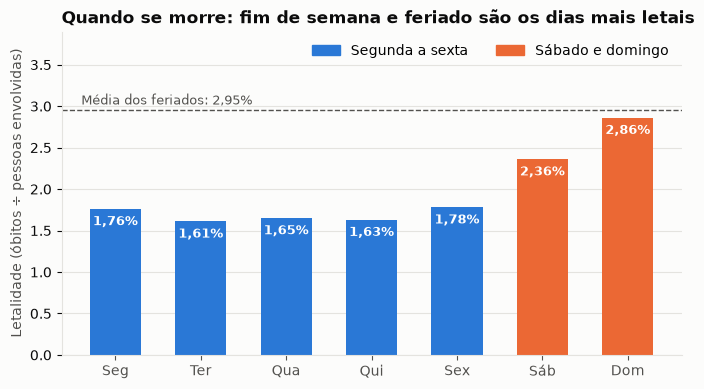

In [21]:
# Gráfico 3: letalidade por dia da semana, com a média dos feriados como referência
CURTO = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
feriado = float(tipo_dia.loc[tipo_dia["tipo_dia"] == "FERIADO", "letalidade"].iloc[0])

fig, ax = plt.subplots(figsize=(8, 4.2))
cores = [LARANJA if d >= 6 else AZUL for d in dias["dia_semana"]]
barras = ax.bar(CURTO, dias["letalidade"], width=0.6, color=cores)
for barra in barras:   # valor dentro da barra, para não encostar na linha dos feriados
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() - 0.08, br(barra.get_height(), 2) + "%",
            ha="center", va="top", fontsize=9, color="white", fontweight="bold")
ax.axhline(feriado, color=TEXTO_2, linestyle="--", linewidth=1)
ax.text(-0.4, feriado + 0.07, f"Média dos feriados: {br(feriado, 2)}%", fontsize=9, color=TEXTO_2)
ax.set_ylabel("Letalidade (óbitos ÷ pessoas envolvidas)")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, 3.9)
ax.set_title("Quando se morre: fim de semana e feriado são os dias mais letais")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="Segunda a sexta"), Patch(color=LARANJA, label="Sábado e domingo")],
          loc="upper right", ncol=2)
salvar(fig, "analise_3_quando_se_morre.png")
plt.show()

## 6. Insight transversal: mortos e sobreviventes são registrados de forma diferente

In [22]:
# % de campos não informados em cada grupo
consulta("qualidade_preenchimento")

,grupo,escolaridade,profissao,idade,tipo_via,gravidade
0,MORTOS,100.0,55.7,6.3,5.8,0.0
1,SOBREVIVENTES,77.9,9.9,0.9,0.0,8.9


## 7. Resumo

- **Quem morre:** a moto responde por 40,3% dos óbitos, com letalidade de 2,31% (o dobro do automóvel, 1,18%), e as mortes de moto cresceram 17,3% de 2021 a 2023. 89,5% dos motociclistas mortos pilotavam; 89% eram homens, com idade mediana de 31 anos. O pedestre é 5,7% das pessoas e 22,8% dos óbitos, e sua letalidade vai de 2,3% (até 17 anos) a 17,6% (80 anos ou mais).
- **Onde se morre:** a rodovia tem 16,6% das pessoas e 43,7% dos óbitos (letalidade 5,16% contra 1,19% na via urbana). O pedestre atropelado em rodovia morre em 38,4% dos casos. 81% das mortes acontecem no mesmo dia. Registro e Itapeva são as regiões mais letais, porque a maior parte dos óbitos delas é em rodovia.
- **Quando se morre:** o fim de semana tem 29,6% das pessoas e 39,2% dos óbitos; domingo é o dia mais letal (2,86%). O feriado tem menos pessoas envolvidas por dia que o dia útil, mas 55% mais óbitos por dia (letalidade 2,95%). No fim de semana a letalidade da moto dobra (3,64% contra 1,82%).
- **Qualidade dos dados:** escolaridade está vazia em 100% dos mortos e profissão em 55,7%, contra 77,9% e 9,9% dos sobreviventes. Por isso essas colunas não entram nas análises de risco.

O texto completo está na seção 6 de `docs/relatorio/relatorio.md`.